# 04 - Detection & classification benchmark

Companion notebook to `results/runs.jsonl` and `results/figures/bench_*.png`.
Event-level detection (no point-adjusted F1) on the temporal test split and the
household hold-out, plus the supervised type/origin classifier.

Prerequisites: build the benchmark first, e.g.
`python -m energymind.benchmark --prevalence 0.05 --seeds 1 2 3`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

from energymind import benchmark_plots as B, io
from energymind.config import load_settings

warnings.filterwarnings("ignore", category=FutureWarning)
%config InlineBackend.figure_format = "png"
plt.rcParams["figure.dpi"] = 110

PREF, SEED = 0.05, 1
settings = load_settings()
runs = B.load_runs()
FIG = io.resolve("results/figures")
print(f"{len(runs)} runs | {runs['model'].nunique()} models | seeds {sorted(runs['seed'].unique())}")

123 runs | 26 models | seeds [np.int64(1), np.int64(2), np.int64(3)]


## Detection at a glance

Event-F1 at the fixed false-alarm budget (1 per household-week), event-level
threshold selection on validation, mean over seeds. `.oracle` is the constrained-free
ceiling for the same score.

In [2]:
det = runs[(runs.task == "detection") & (runs.split == "test")].copy()
table = (
    det.groupby(["model", "thresholding"])
    .agg(F1=("event_f1", "mean"), sd=("event_f1", "std"), recall=("event_recall", "mean"),
         precision=("alert_precision", "mean"), pr_auc=("pr_auc", "mean"),
         fa=("fa_per_household_week", "mean"))
    .round(3)
    .sort_values("F1", ascending=False)
)
table.style.hide(axis="index")

F1,sd,recall,precision,pr_auc,fa
0.896000,0.020000,0.867000,0.929000,0.722000,1.679000
0.894000,0.020000,0.873000,0.916000,0.722000,1.628000
0.891000,0.014000,0.837000,0.954000,0.722000,0.769000
0.683000,0.027000,0.632000,0.750000,0.427000,3.717000
0.656000,0.018000,0.659000,0.658000,0.427000,6.069000
0.577000,0.034000,0.484000,0.716000,0.267000,2.322000
0.561000,0.057000,0.405000,0.942000,0.427000,0.515000
0.561000,0.050000,0.403000,0.933000,0.267000,0.428000
0.552000,0.053000,0.395000,0.947000,0.267000,0.443000
0.453000,0.060000,0.446000,0.464000,0.307000,7.972000


## Classification (type + origin)

LightGBM vs Random Forest, isotonic-calibrated, on train events; chosen by
macro-F1 on validation; reported on test.

In [3]:
clf = runs[runs.task == "classification"].copy()
summary = (
    clf.groupby("model")[["type_macro_f1", "origin_accuracy", "origin_ece"]]
    .agg(["mean", "std"])
    .round(3)
)
summary.style.hide(axis="index")

## Leaderboard and trade-off

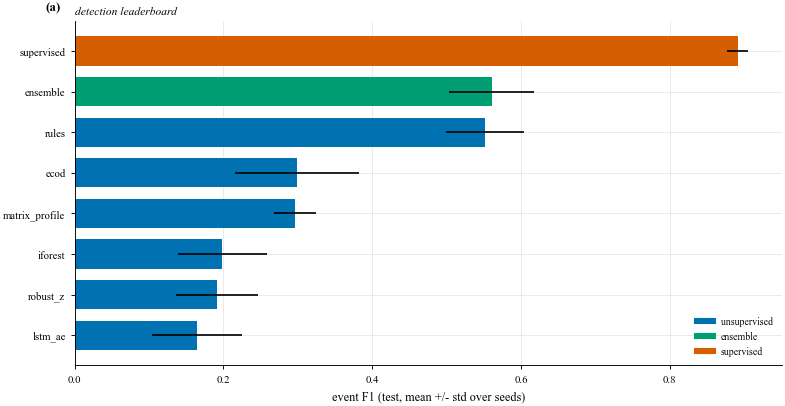

In [4]:
B.fig_detection_leaderboard(runs, FIG)
plt.show()

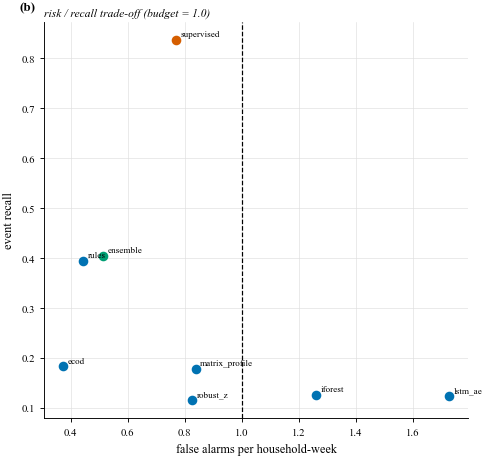

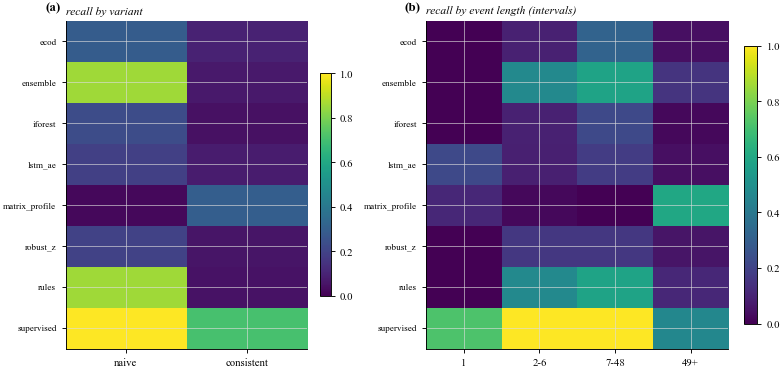

In [5]:
B.fig_detector_tradeoff(runs, FIG)
plt.show()
B.fig_recall_breakdown(runs, FIG)
plt.show()

## Representative run (score distributions, PR curves, classifier)

Computed once for prevalence 5%, seed 1 (the LSTM-AE row is taken from
`runs.jsonl` to keep the notebook quick).

In [6]:
data = B.prepare_run(settings, prevalence=PREF, seed=SEED)
print("detectors:", list(data["scores"]))
print("events:", len(data["events"].anomaly_id.unique()))

detectors: ['robust_z', 'rules', 'iforest', 'ecod', 'matrix_profile', 'ensemble', 'supervised']
events: 290


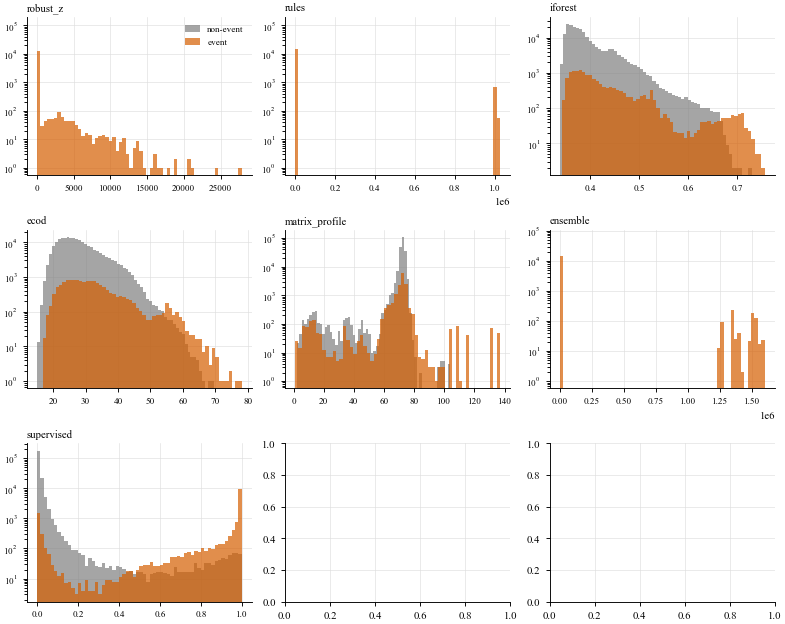

C:\Users\aming\OneDrive\Desktop\tsyp\EnergyMind\src\energymind\eda_plots.py:146: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.savefig(out / f"{name}.png")
C:\Users\aming\OneDrive\Desktop\tsyp\EnergyMind\src\energymind\eda_plots.py:147: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.savefig(out / f"{name}.pdf")
c:\Users\aming\AppData\Local\Programs\Python\Python311\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


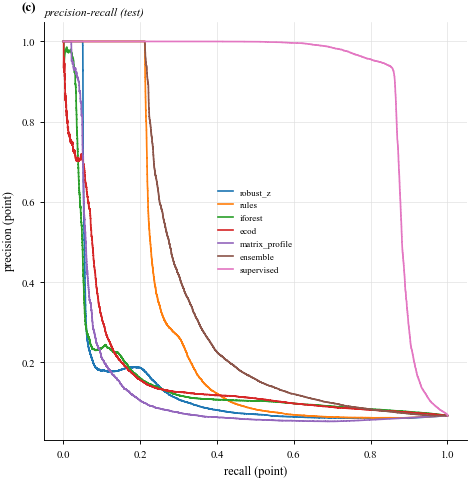

In [7]:
B.fig_score_distributions(data["frame"], data["scores"], data["events"], FIG)
plt.show()
B.fig_pr_curves(data["frame"], data["scores"], data["events"], FIG)
plt.show()

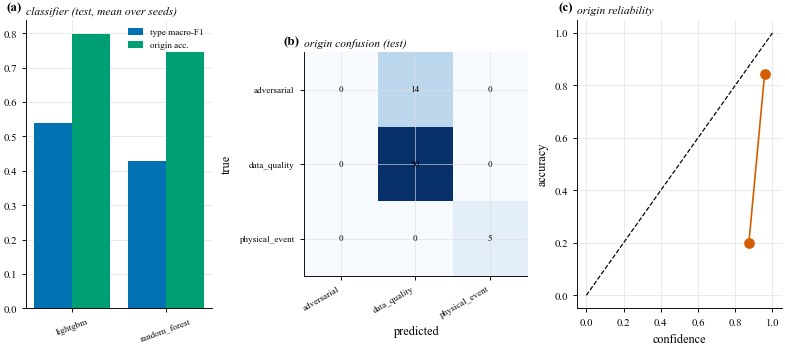

In [8]:
if len(data["classes"]):
    B.fig_classifier(runs, data["confusion"], data["classes"], data["reliability"], FIG)
    plt.show()

## Notes

* Detection is **event-level** (`event_f1`); precision is measured over alerts,
  so no point-adjusted F1 is used.
* `rules` leads the unsupervised set; the supervised model is the labelled
  upper bound and is reported separately; the ensemble improves PR-AUC.
* `recall_by_variant` and `recall_by_length` (in `runs.jsonl`) localise the
  misses: naive > consistent, and short events are the hardest.